In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm


from pygraphon.graphons.common_graphon_functions import graphon_log
from pygraphon.utils.utils_graph import edge_density
from pygraphon.graphons.StepGraphon import StepGraphon
from pygraphon.plots.plot_matrices import spy

from pygraphon.estimators import *
from pygraphon.norm import MseProbaEdge

In [3]:
from pygraphon.plots import plot as plot_step_graphon
def fit_and_show(estimator,A):
	print(estimator.__class__.__name__)
	estimator.fit(A)
    
	fig, ax = plt.subplots(1, 2, figsize=(10, 5))
	fig.subplots_adjust(right=0.9)
	cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
	im = ax[1].imshow(estimator.get_edge_connectivity(), cmap='jet')
	plot_step_graphon(estimator.get_graphon(), fig=fig, ax=ax[0], colormap="jet")
	plt.colorbar(im, cax=cbar_ax)
	plt.show()

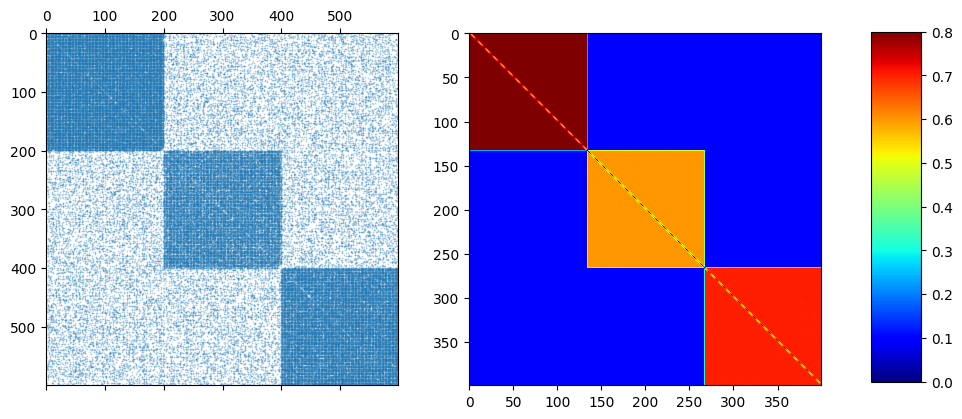

In [10]:
#Set the matrix of theta
graphon_matrix = np.array([[0.8,0.1,0.1],[0.1,0.6,0.1],[0.1,0.1,0.7]])
#set up normalised graphon with graphon
graphon = StepGraphon(graphon_matrix,1/3)
#graphon = graphon_log

A = graphon.draw(rho = 1,n = 600, exchangeable=False)
norm = MseProbaEdge(n_nodes = 500)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im = ax[1].imshow(graphon._get_edge_probabilities(400,False,True), cmap='jet')
_ = spy(A, ax=ax[0])
plt.colorbar(im, cax=cbar_ax)
plt.show()

HistogramEstimator


Log likelihood: -1.3670:   1%|          | 5/500 [00:02<04:00,  2.06it/s]


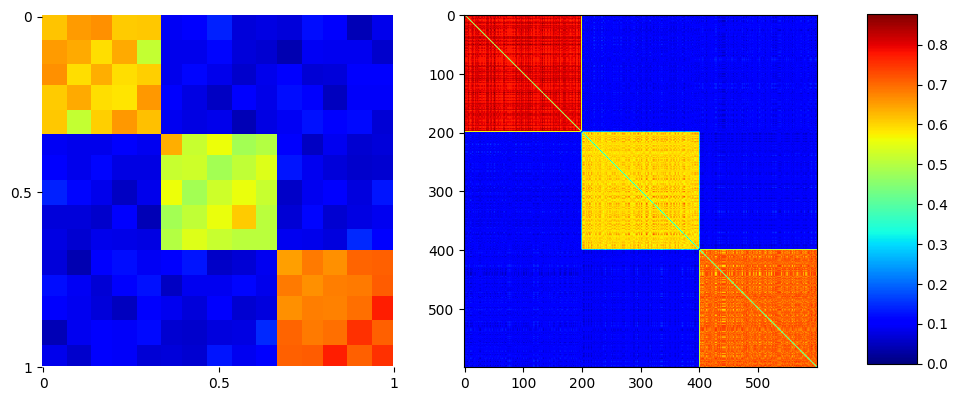

In [16]:
fit_and_show(HistogramEstimator(),A)
fit_and_show(SAS(h=200),A)
fit_and_show(USVT(),A)
#fit_and_show(Completion(),A)

In [ ]:
fit_and_show(LG(K=3),A)
fit_and_show(SBA(),A)
fit_and_show(NBDsmooth(),A)

# Test on pollblog dataset

yep that's the only one where we have a number

In [ ]:
import networkx as nx
G = nx.read_edgelist("network.csv/edges.csv", delimiter = ",", create_using=nx.Graph())
A = nx.to_numpy_array(G)
A = A[np.sum(A, axis = 1) > 0].astype(int)
A[np.diag_indices_from(A)] = 0

In [ ]:
my_hist = HistogramEstimator()
my_hist.fit(graph= A, bandwidthHist= None,absTol = 1e-10, past_non_improving= 100)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im = ax[1].imshow(my_hist.get_graphon()._get_edge_probabilities(17,False,True), cmap='jet')
ax[0].imshow(my_hist.get_edge_connectivity(), cmap='jet')
plt.colorbar(im, cax=cbar_ax)
plt.show()

In [ ]:
hist = HistogramEstimator(method = "matlab")
hist.fit(graph= A, bandwidthHist= None)
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
fig.subplots_adjust(right=0.9)
cbar_ax = fig.add_axes([0.95, 0.15, 0.05, 0.7])
im = ax[1].imshow(hist.get_graphon()._get_edge_probabilities(17,False,True), cmap='jet')
ax[0].imshow(hist.get_edge_connectivity(), cmap='jet')
plt.colorbar(im, cax=cbar_ax)
plt.show()